In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# import time
# import copy
import gc
import math

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from utils import get_opt, get_loaders, eval_ppl

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Load

## Model

In [3]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV);

## Datasets

In [4]:
n_samples = 16

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


In [5]:
# wiki_dataloader, wiki_testloader = get_loaders(
#     'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
# )

# Architecture

In [6]:
class InstrumentedMLP(nn.Module):
    def __init__(self, mlp):
        super().__init__()
        self.mlp = mlp
        self.saved_output = None
        self.saved_grad = None

    def forward(self, x):
        out = self.mlp(x)

        # save activation
        self.saved_output = out.detach()

        # register hook to save gradient
        def save_grad(grad):
            self.saved_grad = grad

        out.register_hook(save_grad)
        return out

In [7]:
class MaskedMLP(nn.Module):
    def __init__(self, mlp, mask):
        super().__init__()
        self.mlp = mlp
        self.mask = mask

    def forward(self, x):
        return self.mlp(x) * self.mask

In [8]:
model = get_opt(model_name)
model.eval()
model.to(DEV)

for layer in model.model.layers:
    layer.mlp = InstrumentedMLP(layer.mlp)

In [9]:
def token_layer_scores(model):
    scores = []
    
    for layer in model.model.layers:
        mlp = layer.mlp
    
        # (B, T, D)
        y = mlp.saved_output.detach()
        grad = mlp.saved_grad.detach()
        
        # first-order Taylor importance
        # inner product over hidden dim
        layer_score = (y * grad).sum(dim=-1).abs().cpu()  # (B, T)
        scores.append(layer_score)
        
        del mlp.saved_output, mlp.saved_grad, y, grad, layer_score
    
    # stack into (L, B, T)
    scores = torch.stack(scores)
    return scores


In [10]:
def get_loss(outputs):
    lm_logits = outputs.logits.cpu()
    shift_logits = lm_logits[:, :-1, :].contiguous()
    shift_labels = bx[:, 1:]
    loss_fct = nn.CrossEntropyLoss()
    return loss_fct(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1))

In [11]:
for bx, _ in dataloader[10: 11]:
    outputs = model(bx.to(DEV))
    loss = get_loss(outputs)
    loss.backward()
    scores = token_layer_scores(model)
    break    

In [12]:
# scores shape: (L, B, T)
def apply_temporal_smoothing(scores, window_size=3):
    L, B, T = scores.shape
    # Pad to keep the same sequence length
    padding = window_size // 2
    
    # Average scores across the T dimension
    # (L*B) treated as batch, 1 as channel, T as length
    flat_scores = scores.view(L * B, 1, T)
    smoothed = F.avg_pool1d(flat_scores, kernel_size=window_size, stride=1, padding=padding)
    
    return smoothed.view(L, B, T)

In [13]:
# scores = apply_temporal_smoothing(scores)

In [14]:
scores_2d = scores.squeeze(1)[:, ::32]

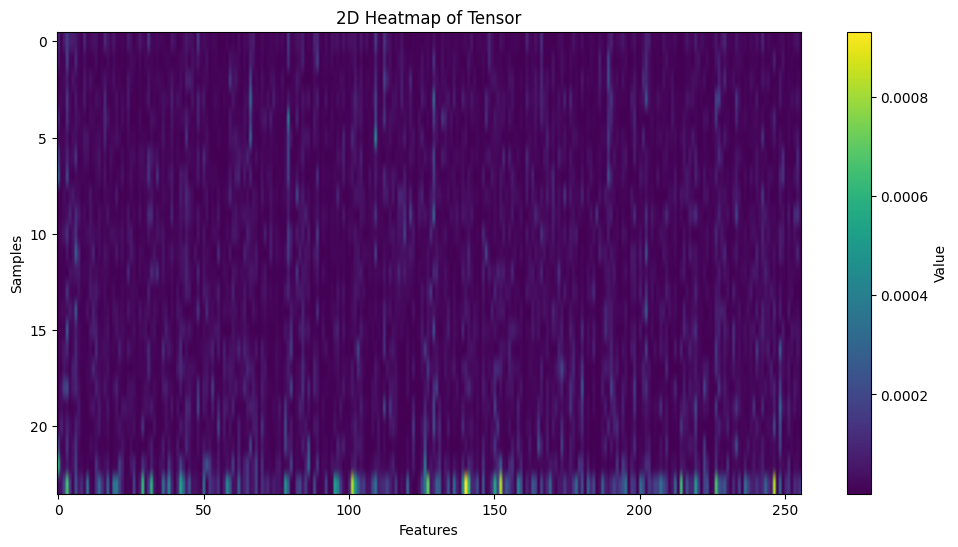

In [15]:
plt.figure(figsize=(12, 6))
plt.imshow(scores_2d.float().numpy(), aspect='auto', cmap='viridis')
plt.colorbar(label='Value')
plt.xlabel('Features')
plt.ylabel('Samples')
plt.title('2D Heatmap of Tensor')
plt.show()

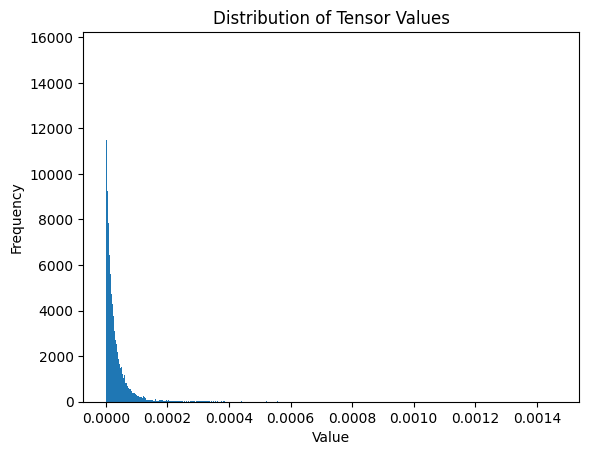

In [16]:
scores_1d = scores.flatten().float()
plt.hist(scores_1d, bins=1000)
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Distribution of Tensor Values")
plt.show()

In [17]:
L, B, T = scores.shape
flat_scores = scores.view(-1)
skip_ratio = 0.3

k = int((1 - skip_ratio) * flat_scores.numel())

topk_vals, topk_idx = torch.topk(flat_scores, k)

mask = torch.zeros_like(flat_scores)
mask[topk_idx] = 1.0

mask = mask.view(L, B, T).to(DEV)

In [18]:
del model
gc.collect()
torch.cuda.empty_cache()

In [19]:
model = get_opt(model_name)
model.eval()
model.to(DEV)

for i, layer in enumerate(model.model.layers):
    layer.mlp = MaskedMLP(layer.mlp, mask[i].unsqueeze(-1))

In [20]:
@torch.no_grad()
def eval_sample_ppl(model, sample):
    input_ids, labels = sample
    batch = {"input_ids": input_ids.to(DEV), "labels": labels.to(DEV)}
    
    outputs = model(**batch)
    return torch.exp(outputs.loss).item()

In [21]:
eval_sample_ppl(model, dataloader[10])

686759.3125

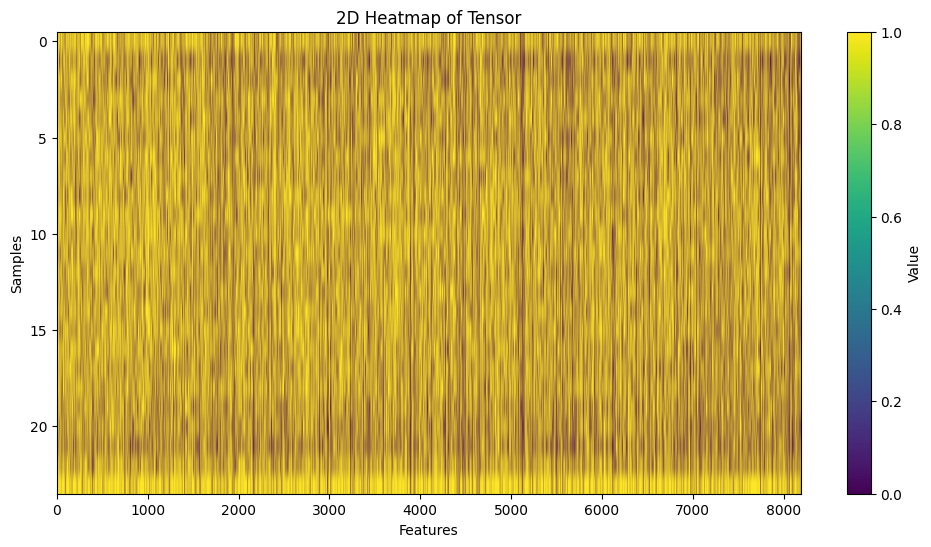

In [22]:
mask_2d = mask.squeeze(1).cpu()
plt.figure(figsize=(12, 6))
plt.imshow(mask_2d.float().numpy(), aspect='auto', cmap='viridis')
plt.colorbar(label='Value')
plt.xlabel('Features')
plt.ylabel('Samples')
plt.title('2D Heatmap of Tensor')
plt.show()